# jPCA on the real Churchland et al. 2012 data

This notebook runs **our own pipeline** (`jpca_core.py`) on the actual data distributed
with the original jPCA code release (`exampleData.mat`, Churchland lab website;
mirrored in the nwb4edu repo). Notebook 01's data is synthetic; this is the real thing.

**What the data is** (from the 2012 paper): M1/PMd **array** recordings during the
"maze task" — straight reaches and reaches curved around barriers. 108 conditions
(4 sets of 27 target/barrier arrangements), 218 units, firing rates sampled every
10 ms starting 50 ms before movement onset. With 218 units it matches the paper's
"N-array" dataset (monkey N; Figure 3f) — J-array had 146 isolations. Note: this is
the *maze* task data — the 8-target center-out sets are different datasets (see
README for links); the straight reaches are a subset of the 108 conditions here.

The data is already distributed as smoothed firing rates, so we skip the smoothing
step of `preprocess` and keep only soft-normalization + cross-condition mean subtraction.

**The dynamical-systems approach.** Instead of reading neurons one at a time, treat the
whole population as ONE point moving through "neuron space" (one axis per neuron) — one
**trajectory** per condition — and fit a law of motion to those trajectories:
**dX/dt = M·X**, "where the state is heading = one fixed matrix × where it is". jPCA is
exactly that idea, with one constraint on M.

**The constraint: a skew-symmetric matrix.** Any matrix splits into a symmetric part
(which stretches/shrinks the state — growth and decay) and a **skew-symmetric** part
(M = −Mᵀ), which only *rotates* the state. A skew-symmetric matrix has purely imaginary
eigenvalues in ±iω pairs, and each pair defines one plane in which the state rotates at
frequency ω/2π. jPCA keeps only this rotational part of the fitted dynamics. (Notebook
02 walks through all of this math slowly, by hand.)

**The pipeline, step by step** — each step below gets its own cell(s):

1. load the real data and look at single neurons,
2. preprocess (soft-normalize, subtract the condition mean — the data is already smoothed),
3. stack the conditions and PCA down to 6 latent dimensions,
4. fit dZ/dt = M·Z with M constrained to be skew-symmetric,
5. eigendecompose M → rotation planes and frequencies; align the axes within each plane,
6. project the trajectories into the top planes → the loop figure, first on the full
   window, then on the paper's first-200-ms window.

108 conditions | 218 neurons | 61 time points
time axis (ms): -50 ... 550 step 10


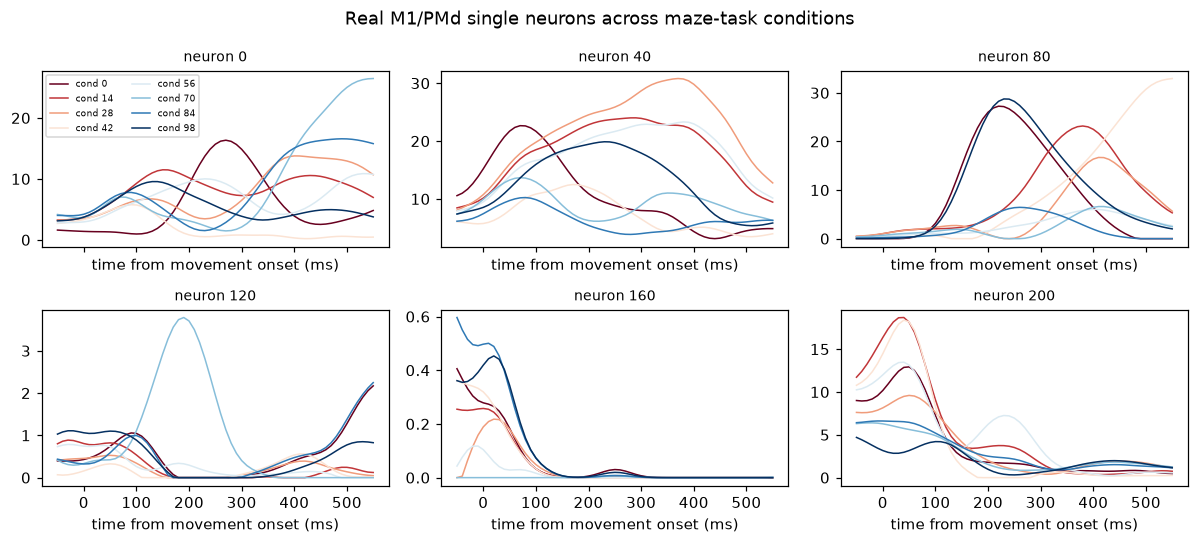

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from jpca_core import *
%matplotlib inline
plt.rcParams['figure.dpi'] = 110

# --- Step 1: load the real data (scipy only; the .mat predates v7.3) --------
from scipy.io import loadmat

# squeeze_me collapses the (1, 108) struct array to a plain (108,) record
# array; all conditions share one time axis, so the whole dataset stacks in
# a single call -- no per-condition loop.
Data = loadmat('data/exampleData.mat', squeeze_me=True)['Data']  # fields: A, times
rates_ctn = np.stack(Data['A'])                   # (C, T, N) = (108, 61, 218)
times = np.asarray(Data[0]['times']).ravel()      # time axis in ms (taken from condition 0)
for c in range(Data.size):                        # check that every condition uses this same axis
    assert np.array_equal(np.asarray(Data[c]['times']).ravel(), times)

C, T, N = rates_ctn.shape
rates_real = rates_ctn.transpose(2, 0, 1)   # reorder to (N, C, T) -- like MATLAB permute(x, [3 1 2])
print(f'{C} conditions | {N} neurons | {T} time points')
print('time axis (ms):', times[0], '...', times[-1], 'step', times[1]-times[0])

# --- nwb4edu-style exploration: example neurons across conditions ----------
# (colors here only distinguish conditions; the state-space figures below use
# the paper's convention: color = sorted starting jPC1, i.e. preparatory state)
neurons_to_show = [0, 40, 80, 120, 160, 200]      # 6 example neurons, one per panel
conds_to_show = list(range(0, C, 14))             # every 14th condition -> 8 conditions

fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True)   # grid of 2 rows x 3 columns
for panel in range(6):
    ax = axes[panel // 3, panel % 3]              # panel 0..5 -> its (row, col) in the grid
    neuron = neurons_to_show[panel]
    for k in range(len(conds_to_show)):
        cond = conds_to_show[k]
        # color from the blue->red colormap: 0.0 = blue (first condition), 1.0 = red (last)
        color = plt.cm.RdBu(k / (len(conds_to_show) - 1))
        ax.plot(times, rates_real[neuron, cond, :], color=color, linewidth=1)
    ax.set_title(f'neuron {neuron}', fontsize=9)
    ax.set_xlabel('time from movement onset (ms)')

legend_labels = []
for cond in conds_to_show:
    legend_labels.append(f'cond {cond}')
axes[0, 0].legend(legend_labels, fontsize=6, ncol=2)
fig.suptitle('Real M1/PMd single neurons across maze-task conditions')
fig.tight_layout(); plt.show()

**The peak-time-sorted raster, on real data.** Before any jPCA: average each neuron
across all 108 conditions, sort neurons by their peak time, and look at one condition.
The "traveling wave" appears — this is exactly the Kuzmina et al. construction, on the
very dataset Churchland analyzed. Keep this circularity in mind when the rotation
appears below (Notebook 01 unpacks it).

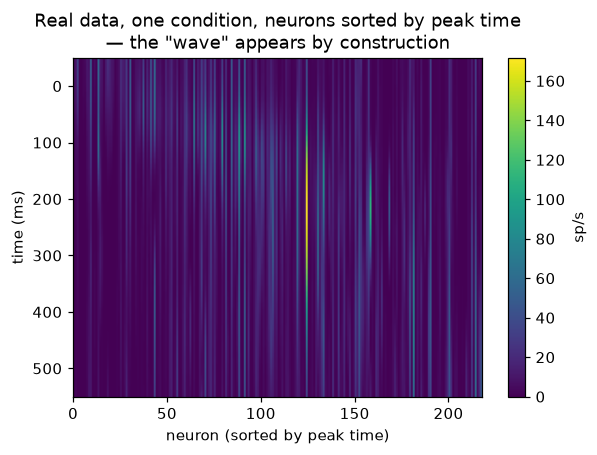

In [2]:
mean_rates = rates_real.mean(axis=1)                      # (N, T) across conditions
peak_order = np.argsort(np.argmax(mean_rates, axis=1))
plt.figure(figsize=(6, 4))
plt.imshow(rates_real[peak_order][:, 10].T, aspect='auto', cmap='viridis',
           extent=[0, N, times[-1], times[0]])
plt.xlabel('neuron (sorted by peak time)'); plt.ylabel('time (ms)')
plt.title('Real data, one condition, neurons sorted by peak time\n— the "wave" appears by construction')
plt.colorbar(label='sp/s'); plt.show()

**Step 2 — preprocessing on the real data, before → after.** The same steps as
everywhere in this repo, except the smoothing step is skipped (`smooth_sd_ms=0`): this
file already contains smoothed firing rates. Watch the two active steps —
soft-normalization and condition-mean subtraction — on the most strongly modulated
unit and a quiet-but-responsive one (10th percentile of range):

per-unit range before normalization: 0.2 .. 170.1 sp/s
unit 206: range 170.1 sp/s  ->  0.97 after normalization
unit 21: range 6.6 sp/s  ->  0.57 after normalization
the +5 sp/s "soft" constant: without it unit 21 would be scaled up 25.9x more than unit 206; with it, only 15.1x


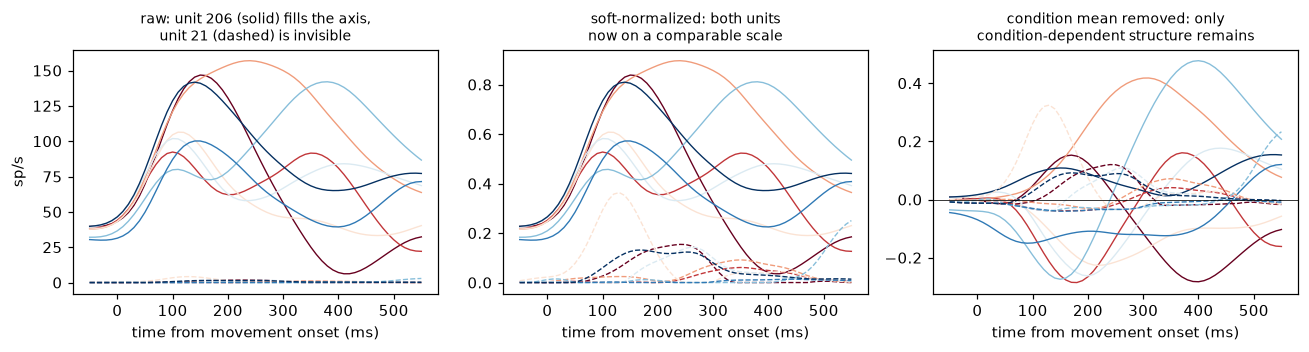

check: step-by-step == preprocess(): True


In [3]:
# --- Step 2: what the preprocessing does to the real data, before -> after --
spread = rates_real.max(axis=(1, 2)) - rates_real.min(axis=(1, 2))     # per-unit range
normed = rates_real / (spread + 5.0)[:, None, None]                    # 2. soft-normalize
final = normed - normed.mean(axis=1, keepdims=True)                    # 3. subtract condition mean

hi = int(np.argmax(spread))                       # most modulated unit
lo = int(np.argsort(spread)[len(spread) // 10])   # 10th percentile: quiet but responsive
print(f'per-unit range before normalization: {spread.min():.1f} .. {spread.max():.1f} sp/s')
print(f'unit {hi}: range {spread[hi]:.1f} sp/s  ->  {np.ptp(normed[hi]):.2f} after normalization')
print(f'unit {lo}: range {spread[lo]:.1f} sp/s  ->  {np.ptp(normed[lo]):.2f} after normalization')
print(f'the +5 sp/s "soft" constant: without it unit {lo} would be scaled up '
      f'{spread[hi] / spread[lo]:.1f}x more than unit {hi}; with it, only '
      f'{(spread[hi] + 5) / (spread[lo] + 5):.1f}x')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for u, ls in [(hi, '-'), (lo, '--')]:
    for k, cond in enumerate(conds_to_show):
        color = plt.cm.RdBu(k / (len(conds_to_show) - 1))   # same conditions as above
        axes[0].plot(times, rates_real[u, cond], color=color, lw=0.9, ls=ls)
        axes[1].plot(times, normed[u, cond], color=color, lw=0.9, ls=ls)
        axes[2].plot(times, final[u, cond], color=color, lw=0.9, ls=ls)
axes[0].set_title(f'raw: unit {hi} (solid) fills the axis,\nunit {lo} (dashed) is invisible',
                  fontsize=9)
axes[1].set_title('soft-normalized: both units\nnow on a comparable scale', fontsize=9)
axes[2].axhline(0, color='k', lw=0.5)
axes[2].set_title('condition mean removed: only\ncondition-dependent structure remains',
                  fontsize=9)
for ax in axes:
    ax.set_xlabel('time from movement onset (ms)')
axes[0].set_ylabel('sp/s')
fig.tight_layout(); plt.show()

rates_p = preprocess(rates_real, bin_ms=10, smooth_sd_ms=0)   # one call, already smoothed
print('check: step-by-step == preprocess():', np.allclose(final, rates_p))

**Step 3 — stack the conditions and PCA down to 6 latent dimensions.** Every
(condition, time) pair becomes one column of a big state matrix; PCA then finds the 6
directions that carry the most variance. Everything jPCA does from here happens inside
that 6-D space — it only picks new axes within it.

In [4]:
# --- Step 3: stack conditions end to end, then PCA ---------------------------
from sklearn.decomposition import PCA

n_pcs, dt_s = 6, 0.01                             # 6 PCs -> 3 planes; 10 ms bins

# Stack conditions end to end: every (condition, time) pair is one sample.
X = rates_p.reshape(N, C * T)                     # (N, C*T)

# PCA down to the top 6 PCs. Z is the population state in PC space.
pca = PCA(n_components=n_pcs)
Z = pca.fit_transform(X.T).T                      # (6, C*T)
print('PCA: %d neurons -> %d PCs holding %.0f%% of the variance'
      % (N, n_pcs, 100 * pca.explained_variance_ratio_.sum()))

PCA: 218 neurons -> 6 PCs holding 48% of the variance


**Step 4 — fit the law of motion, rotation only.** Fit dZ = M·Z between adjacent
time bins by ordinary least squares, first unconstrained (M may stretch, shrink, and
rotate), then restricted to skew-symmetric M — rotation only. Only the 15 entries above
the diagonal of a 6×6 skew matrix are free; conjugate gradients minimize ‖dZ − M·Z‖²
over them directly, starting from the closed-form projection (M_full − M_fullᵀ)/2 —
the same constrained fit as the original 2012 toolbox.

Comparing the two R² values tells you how much of the motion is rotational. One metric
subtlety: this whole-space R² is measured across *all six* latent dimensions, including
non-rotational ones whose derivative no skew-symmetric M can fit — so it is diluted.
The honest per-plane metric, the in-plane R², comes in step 6.

In [5]:
# --- Step 4: least-squares fit of dZ = M Z, then the skew-symmetric-only fit -
from scipy.optimize import minimize

# State and its change over one time step. (As in jpca(), the difference runs
# along the stacked axis, so it also includes the C-1 jumps from the end of one
# condition to the start of the next.)
Z0 = Z[:, :-1]                                    # state now
dZ = np.diff(Z, axis=1)                           # state next - state now

# a) unconstrained least squares: M_full may stretch, shrink and rotate
M_full = np.linalg.lstsq(Z0.T, dZ.T, rcond=None)[0].T
r2_full = 1.0 - np.sum((dZ - M_full @ Z0) ** 2) / np.sum(dZ ** 2)

# b) skew-symmetric only (M = -M^T): such a matrix can only rotate.
#    (M_full - M_full^T)/2 is the closed-form starting guess; conjugate
#    gradients then finds the best skew-symmetric M. Only the entries above
#    the diagonal are free (15 numbers for 6x6), so we optimize those.
iu = np.triu_indices(n_pcs, k=1)

def vec2mat(h):                                   # 15 numbers -> 6x6 skew matrix
    M = np.zeros((n_pcs, n_pcs))
    M[iu] = h
    return M - M.T

def objective(h):                                 # squared error of dZ = M Z0
    return 0.5 * np.sum((Z0.T @ vec2mat(h).T - dZ.T) ** 2)

def gradient(h):
    dM = (Z0 @ Z0.T @ vec2mat(h).T) - (Z0 @ dZ.T)
    return (dM.T - dM)[iu]

M_start = 0.5 * (M_full - M_full.T)
fit = minimize(objective, M_start[iu], jac=gradient, method='CG',
               options=dict(maxiter=10000, gtol=1e-4))
M_skew = vec2mat(fit.x)

r2 = 1.0 - np.sum((dZ - M_skew @ Z0) ** 2) / np.sum(dZ ** 2)
print('fit R^2: any linear dynamics %.3f | rotation only %.3f' % (r2_full, r2))

fit R^2: any linear dynamics 0.165 | rotation only 0.146


**Step 5 — eigenvalues → planes and frequencies.** A skew-symmetric matrix has
purely imaginary eigenvalues in conjugate pairs ±iω: each pair is one rotation plane,
ω its angular speed. The real and imaginary parts of each eigenvector span the plane
(QR makes them an orthonormal basis). Finally, a display convention from the original
toolbox: the axes *within* each plane are rotated so the first-bin — preparatory —
states lie along jPC1; this changes nothing about the fit or the variances.

In [6]:
# --- Step 5: eigendecompose M_skew -> rotation planes, frequencies, axes ----
eigvals, eigvecs = np.linalg.eig(M_skew)
print('eigenvalues (imaginary part):', np.round(np.sort(eigvals.imag), 4))
planes, freqs_hz = [], []
for i in np.argsort(-eigvals.imag):               # fastest rotation first
    if eigvals[i].imag <= 1e-10:
        break                                     # the rest are the -i*w partners
    v = eigvecs[:, i]
    Q, _ = np.linalg.qr(np.column_stack([v.real, v.imag]))
    planes.append(Q)                              # (6, 2): PC space -> this plane
    freqs_hz.append(eigvals[i].imag / (2 * np.pi * dt_s))   # rad/bin -> Hz

# Display convention: the two axes inside a plane are arbitrary up to a
# rotation, so turn them until the starting (first-bin, preparatory) states
# spread along jPC1. Pure in-plane rotation: nothing about the fit changes.
Zc = Z.reshape(n_pcs, C, T)
for k, Q in enumerate(planes):
    coords = np.einsum('ij,jct->ict', Q.T, Zc)    # (2, C, T) in-plane trajectories
    start = coords[:, :, 0].T                     # (C, 2) starting states
    rot = PCA(n_components=2).fit(start).components_
    if np.linalg.det(rot) < 0:                    # keep the basis right-handed
        rot[1] = -rot[1]
    new = np.einsum('ij,jct->ict', rot, coords)
    if np.abs(new[1]).max() > new[1].max():       # largest jPC2 excursion positive
        rot = -rot
    planes[k] = Q @ rot.T
print('rotation frequencies (Hz):', np.round(freqs_hz, 2))

eigenvalues (imaginary part): [-0.0781 -0.0326 -0.0024  0.0024  0.0326  0.0781]
rotation frequencies (Hz): [1.24 0.52 0.04]


**Step 6 — project the trajectories into the top planes.** Two dot products per time
point — coordinate 1 = a·Z(t), coordinate 2 = b·Z(t), where a and b span the plane —
and plotting one against the other as time runs *is* the famous jPCA loop figure. We
also report each plane's share of the variance and its **in-plane R²** (the rotational
fit restricted to that 2-D plane — the honest per-plane metric, free of the dilution
noted in step 4).

jPC plane 1: 39.5% of variance | in-plane rotation R^2 = +0.07 | 1.24 Hz
jPC plane 2: 31.9% of variance | in-plane rotation R^2 = +0.38 | 0.52 Hz
jPC plane 3: 28.7% of variance | in-plane rotation R^2 = +0.00 | 0.04 Hz


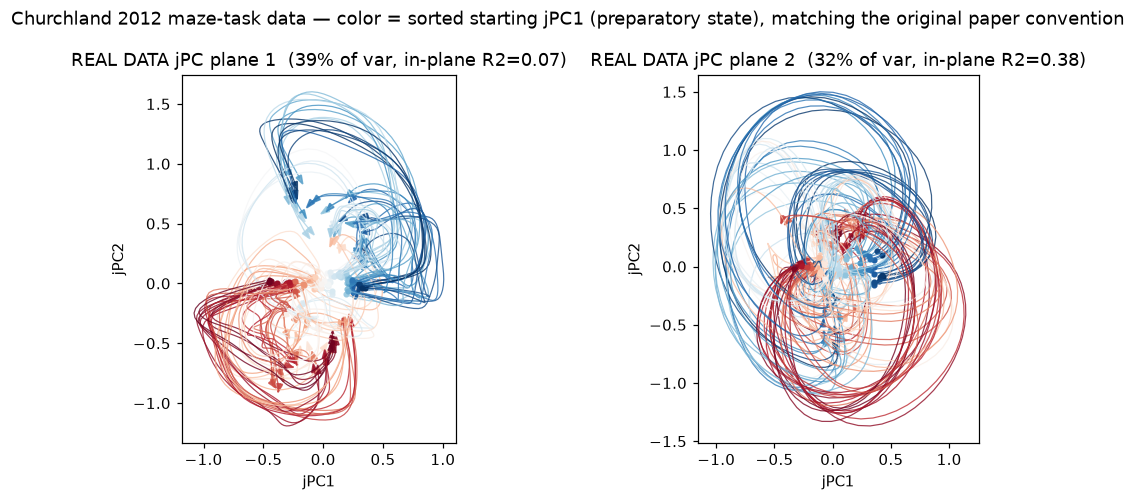

In [7]:
# --- Step 6: project into the jPC planes -> the loop figure ------------------
# Collect the fitted pieces in the same dict layout jpca() returns, so we can
# reuse project_planes() for the projections and in-plane R^2.
res = dict(pca=pca, Z=Z, M_skew=M_skew, r2=r2, eigvals=eigvals,
           planes=planes, freqs_hz=freqs_hz, n_conditions=C, dt_s=dt_s)

projs = project_planes(res)                       # planes ordered by variance
for k, (_, frac, r2p) in enumerate(projs, 1):
    print('jPC plane %d: %4.1f%% of variance | in-plane rotation R^2 = %+.2f | %.2f Hz'
          % (k, 100 * frac, r2p, res['freqs_hz'][k - 1]))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (coords, frac, r2p), k in zip(axes, projs, [1, 2]):
    cols_k = start_ordered_colors(coords)      # color = starting jPC1 (preparatory)
    hw = 0.03 * np.abs(coords).max()
    for c in range(C):
        ax.plot(coords[0, c], coords[1, c], color=cols_k[c], lw=0.8, alpha=0.8)
        ax.plot(coords[0, c, 0], coords[1, c, 0], 'o', color=cols_k[c], ms=3)
        ax.arrow(coords[0, c, -1], coords[1, c, -1],
                 coords[0, c, -1] - coords[0, c, -2],
                 coords[1, c, -1] - coords[1, c, -2],
                 color=cols_k[c], alpha=0.8, head_width=hw, length_includes_head=True)
    ax.set_title(f'REAL DATA jPC plane {k}  ({frac:.0%} of var, in-plane R2={r2p:.2f})')
    ax.set_xlabel('jPC1'); ax.set_ylabel('jPC2'); ax.set_aspect('equal')
fig.suptitle('Churchland 2012 maze-task data — color = sorted starting jPC1 '
             '(preparatory state), matching the original paper convention')
fig.tight_layout(); plt.show()

## The paper's window: the first 200 ms

Why doesn't the figure above look exactly like the paper's Figure 3? Two reasons, in
order of visual impact:

1. **Time window.** The paper plots only the **first 200 ms of movement-related
   activity** per condition; everything above used the full 600 ms supplied in the
   file, so each loop includes the movement-offset / return segment, which doubles
   back and tangles the picture. Below we refit on just −50 to 150 ms — the arcs
   immediately resolve into the sweeping, radiating structure of the paper's panels.
2. **Which dataset.** The clean textbook loops are Figure 3a–b: monkeys B and A,
   28 *straight-reach* conditions recorded with single electrodes. This file is the
   108-condition **array** dataset (curved + straight reaches mixed), whose paper
   panels (e–f) are visibly messier too.

Two conventions of the original toolbox are already visible in the steps above: the
**constrained skew fit** (step 4 refines the closed-form guess by conjugate gradients,
as the 2012 code does) and the **in-plane axis alignment** (step 5 puts the preparatory
states along jPC1). The refit below reuses the one-line `jpca()` — it runs exactly the
steps we just walked through.

Honest caveat: even in the paper's window, the in-plane skew-symmetric fit is weak for
this dataset — the rotation is visually consistent but the linear model in that plane
explains little. The paper's quantitative claim rests on the fit in the full 6-D PC
space, not on clean in-plane fits.

200 ms window: plane 1 46% of var | in-plane rotation R^2 = +0.01 | freqs [0.94 0.63 0.1 ] Hz


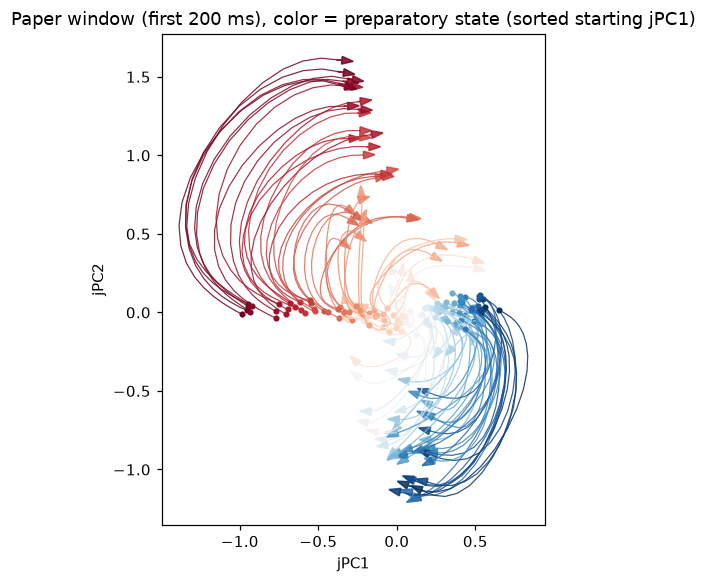

In [8]:
# --- Refit on the paper's analysis window (first 200 ms) ---------------------
k200 = int(np.searchsorted(times, 150))          # -50 .. 150 ms
res200 = jpca(rates_p[:, :, :k200], n_pcs=6, dt_s=0.01)   # same pipeline, one call
coords200, frac200, r2p200 = project_planes(res200)[0]
print('200 ms window: plane 1 %.0f%% of var | in-plane rotation R^2 = %+.2f | freqs %s Hz'
      % (100 * frac200, r2p200, np.round(res200['freqs_hz'], 2)))

fig, ax = plt.subplots(figsize=(6, 5.4))
cols200 = start_ordered_colors(coords200)      # color = sorted starting jPC1
hw = 0.03 * np.abs(coords200).max()
for c in range(C):
    ax.plot(coords200[0, c], coords200[1, c], color=cols200[c], lw=0.8, alpha=0.85)
    ax.plot(coords200[0, c, 0], coords200[1, c, 0], 'o', color=cols200[c], ms=3)
    ax.arrow(coords200[0, c, -1], coords200[1, c, -1],
             coords200[0, c, -1] - coords200[0, c, -2],
             coords200[1, c, -1] - coords200[1, c, -2],
             color=cols200[c], alpha=0.85, head_width=hw, length_includes_head=True)
ax.set_title('Paper window (first 200 ms), color = preparatory state (sorted starting jPC1)')
ax.set_xlabel('jPC1'); ax.set_ylabel('jPC2'); ax.set_aspect('equal')
fig.tight_layout(); plt.show()

## Takeaway

The real data shows the same qualitative structure the 2012 paper reported — nested,
consistently directed loops in the top jPC planes. But look back at the sorted raster
above: the peak-time wave is already there in the raw rates, before any jPCA. So jPCA
did not discover a hidden engine here — it re-displayed an order that exists in the
data. Whether that order has a physical, anatomical address is the question no
electrode-only dataset can answer — and the subject of Notebook 01.